In [8]:
import matplotlib.pyplot as plt
import numpy as np
from siglab_py.util.orderbook_util import OrderBookFeatures, extract_ob_features
from ccxt.binance import binance

In [9]:
OB_DEPTH : int = 1000 # num bids and num asks you're fetching

In [10]:
ticker : str = "SOL/USDT:USDT"
order_notional : float = 1_000_000 * 1 # intended trading order notional
atr_bps : float = 90 # You determine this from separate ATR analysis, for the trading session/time of day/day of week/month you intended to trade
focus_atr_multiple : float = 5 # Focus your analysis, in terms of multiples of atr_bps from mid
price_level_separation_bps : float = 20
wall_threshold_multiplier : float = None # Set to like 3. Default None - i.e. Don't bother compute

In [11]:
exchange = binance()

In [12]:
ob = exchange.fetch_order_book(symbol=ticker, limit=OB_DEPTH)

In [13]:
features = extract_ob_features(
    ob=ob,
    order_notional=order_notional,
    price_level_separation_bps=price_level_separation_bps,
    atr_bps=atr_bps,
    focus_atr_multiple=focus_atr_multiple, 
    wall_threshold_multiplier=wall_threshold_multiplier, 
)
features

{'num_bids': 1000,
 'num_asks': 1000,
 'best_bid': 106.63,
 'best_ask': 106.64,
 'focus_bid': (106.63, 911305.82),
 'focus_ask': (106.64, 857076.55),
 'worst_bid': 96.66,
 'worst_ask': 116.63,
 'mid': 106.63499999999999,
 'best_spread_bps': 0.93782,
 'spread_bps_by_order_notional': 75.34376,
 'focus_spread_bps': 0.93782,
 'knee_spread_bps': 790.6024566192249,
 'worst_spread_bps': 2066.00455,
 'buy_walls': None,
 'sell_walls': None,
 'bid_knee': (102.58, 871526.3699999999),
 'ask_knee': (110.69, 842416.8),
 'slippage_target_bid': (106.18, 207332.53),
 'slippage_target_ask': (106.98, 138544.77),
 'total_bid_volume': 1114169.71,
 'total_ask_volume': 962688.59,
 'imbalance': 0.07293762891767822}

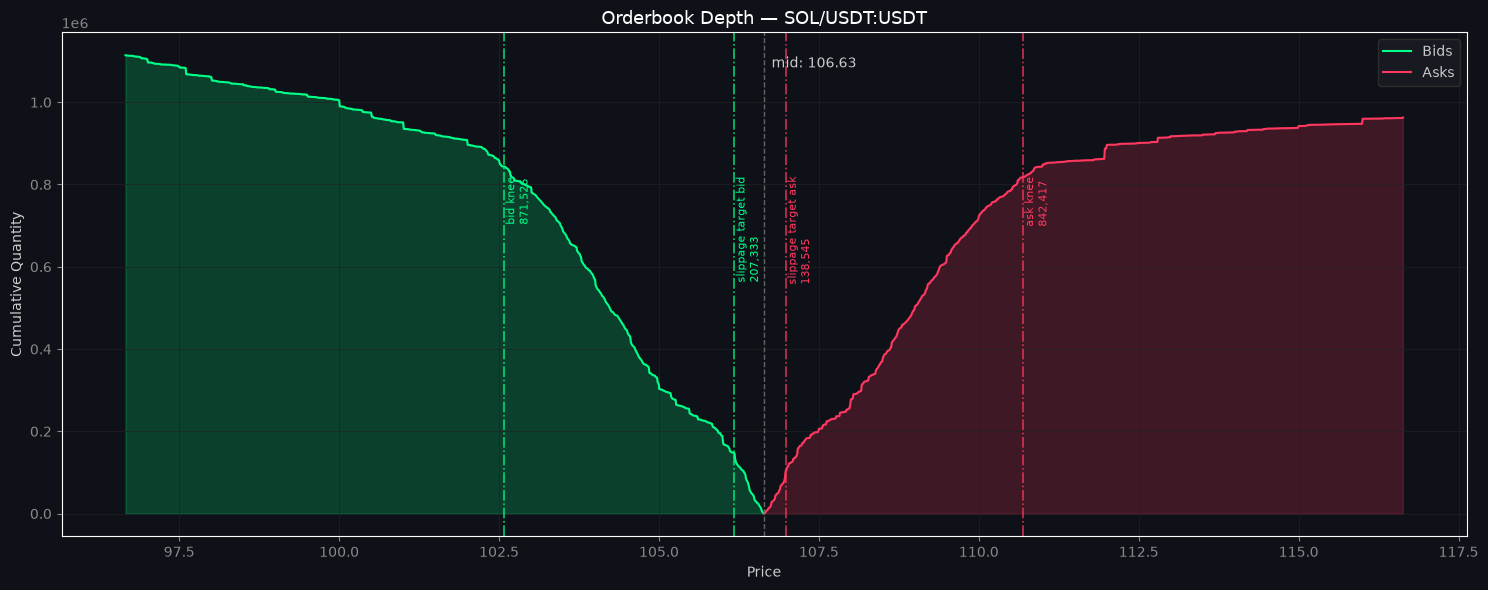

In [14]:
bids = np.array(ob['bids'])
asks = np.array(ob['asks'])
bid_prices, bid_qtys = bids[:, 0], bids[:, 1]
ask_prices, ask_qtys = asks[:, 0], asks[:, 1]
bid_cum = np.cumsum(bid_qtys)
ask_cum = np.cumsum(ask_qtys)

plt.style.use('dark_background')

fig, ax = plt.subplots(figsize=(15, 6))
fig.patch.set_facecolor('#0e1117')
ax.set_facecolor('#0e1117')

ax.plot(bid_prices, bid_cum, color='#00ff88', lw=1.5, label='Bids')
ax.fill_between(bid_prices, bid_cum, color='#00ff88', alpha=0.2)

ax.plot(ask_prices, ask_cum, color='#ff3860', lw=1.5, label='Asks')
ax.fill_between(ask_prices, ask_cum, color='#ff3860', alpha=0.2)

if features['buy_walls']:
    for price, volume in features['buy_walls']:
        ax.axvline(price, color='#00ff88', ls=':', lw=1.2, alpha=0.8)
        ax.text(price, ax.get_ylim()[1] * 0.85, f'  buy wall\n  {volume:,.0f}', color='#00ff88', fontsize=8, va='top', rotation=90)

if features['sell_walls']:
    for price, volume in features['sell_walls']:
        ax.axvline(price, color='#ff3860', ls=':', lw=1.2, alpha=0.8)
        ax.text(price, ax.get_ylim()[1] * 0.85, f'  sell wall\n  {volume:,.0f}', color='#ff3860', fontsize=8, va='top', rotation=90)

if features['spread_bps_by_order_notional']>10:
    slippage_target_bid_price, slippage_target_bid_vol = features['slippage_target_bid']
    slippage_target_ask_price, slippage_target_ask_vol = features['slippage_target_ask']
    ax.axvline(slippage_target_bid_price, color='#00ff88', ls='-.', lw=1.2, alpha=0.8)
    ax.text(slippage_target_bid_price, ax.get_ylim()[1] * 0.70, f'  slippage target bid\n  {slippage_target_bid_vol:,.0f}', color='#00ff88', fontsize=8, va='top', rotation=90)
    ax.axvline(slippage_target_ask_price, color='#ff3860', ls='-.', lw=1.2, alpha=0.8)
    ax.text(slippage_target_ask_price, ax.get_ylim()[1] * 0.70, f'  slippage target ask\n  {slippage_target_ask_vol:,.0f}', color='#ff3860', fontsize=8, va='top', rotation=90)

if features['focus_spread_bps']>10:
    focus_bid_price, focus_bid_vol = features['focus_bid']
    focus_ask_price, focus_ask_vol = features['focus_ask']
    ax.axvline(focus_bid_price, color='#00ff88', ls='-.', lw=1.2, alpha=0.8)
    ax.text(focus_bid_price, ax.get_ylim()[1] * 0.70, f'  focus bid\n  {focus_bid_vol:,.0f}', color='#00ff88', fontsize=8, va='top', rotation=90)
    ax.axvline(focus_ask_price, color='#ff3860', ls='-.', lw=1.2, alpha=0.8)
    ax.text(focus_ask_price, ax.get_ylim()[1] * 0.70, f'  focus ask\n  {focus_ask_vol:,.0f}', color='#ff3860', fontsize=8, va='top', rotation=90)


bid_knee_price, bid_knee_vol = features['bid_knee']
ask_knee_price, ask_knee_vol = features['ask_knee']
ax.axvline(bid_knee_price, color='#00ff88', ls='-.', lw=1.2, alpha=0.8)
ax.text(bid_knee_price, ax.get_ylim()[1] * 0.70, f'  bid knee\n  {bid_knee_vol:,.0f}', color='#00ff88', fontsize=8, va='top', rotation=90)
ax.axvline(ask_knee_price, color='#ff3860', ls='-.', lw=1.2, alpha=0.8)
ax.text(ask_knee_price, ax.get_ylim()[1] * 0.70, f'  ask knee\n  {ask_knee_vol:,.0f}', color='#ff3860', fontsize=8, va='top', rotation=90)

mid = (bid_prices[0] + ask_prices[0]) / 2
ax.axvline(mid, color='#888888', ls='--', lw=1, alpha=0.7)
ax.text(mid, ax.get_ylim()[1] * 0.95, f'  mid: {mid:,.2f}', color='#cccccc', fontsize=10, va='top')

ax.set_xlabel('Price', color='#cccccc')
ax.set_ylabel('Cumulative Quantity', color='#cccccc')
ax.set_title(f'Orderbook Depth — {ticker}', color='#ffffff', fontsize=13)
ax.tick_params(colors='#888888')
ax.grid(True, color='#222222', lw=0.5)
ax.legend(facecolor='#1a1d24', edgecolor='#333333', labelcolor='#cccccc')

plt.tight_layout()
plt.show()